<style>
.jp-RenderedHTMLCommon, .text_cell_render, .rendered_html { color: inherit !important; }
.jp-RenderedHTMLCommon h1, .jp-RenderedHTMLCommon h2, .jp-RenderedHTMLCommon h3, .text_cell_render h1, .text_cell_render h2, .text_cell_render h3 { color: inherit !important; }
</style>

# Лабораторная работа №1

## Предобработка и начало анализа данных с использованием pandas

Датасет: пассажиры Titanic из репозитория seaborn-data. Одна строка соответствует записи о пассажире.

## Цель

Освоить загрузку, исследование, преобразование, очистку, визуализацию и статистический анализ табличных данных.

## Импорт библиотек

In [1]:
# подключаем библиотеки которые понадобятся дальше
import warnings

# убираем предупреждения чтобы они не засоряли вывод
warnings.filterwarnings('ignore')

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, OneHotEncoder
from scipy.stats import chi2_contingency, fisher_exact

# один стиль и размер для всех графиков
sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (8, 5)

## 1. Загрузка данных (`pd.read_csv`)

In [2]:
# читаем csv и получаем обычный датафрейм pandas
df = pd.read_csv('titanic.csv')
print(f'Размер датасета: {df.shape[0]} строк, {df.shape[1]} столбцов')

Размер датасета: 891 строк, 15 столбцов


## 2. Изучение данных

### Первые и последние строки (`head`, `tail`)

In [3]:
# первые пять строк
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [4]:
# теперь последние пять строк
df.tail()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
886,0,2,male,27.0,0,0,13.00,S,Second,man,True,NaN,Southampton,no,True
887,1,1,female,19.0,0,0,30.00,S,First,woman,False,B,Southampton,yes,True
888,0,3,female,NaN,1,2,23.45,S,Third,woman,False,NaN,Southampton,no,False
889,1,1,male,26.0,0,0,30.00,C,First,man,True,C,Cherbourg,yes,True
890,0,3,male,32.0,0,0,7.75,Q,Third,man,True,NaN,Queenstown,no,True


### Структура, типы и столбцы (`info`, `dtypes`, `columns`)

In [5]:
# общая информация по таблице и пропускам
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   survived     891 non-null    int64  
 1   pclass       891 non-null    int64  
 2   sex          891 non-null    str    
 3   age          714 non-null    float64
 4   sibsp        891 non-null    int64  
 5   parch        891 non-null    int64  
 6   fare         891 non-null    float64
 7   embarked     889 non-null    str    
 8   class        891 non-null    str    
 9   who          891 non-null    str    
 10  adult_male   891 non-null    bool   
 11  deck         203 non-null    str    
 12  embark_town  889 non-null    str    
 13  alive        891 non-null    str    
 14  alone        891 non-null    bool   
dtypes: bool(2), float64(2), int64(4), str(7)
memory usage: 92.4 KB


In [6]:
# тип данных каждого столбца
df.dtypes

survived         int64
pclass           int64
sex                str
age            float64
sibsp            int64
parch            int64
fare           float64
embarked           str
class              str
who                str
adult_male        bool
deck               str
embark_town        str
alive              str
alone             bool
dtype: object

In [7]:
# список всех названий столбцов
df.columns.tolist()

['survived',
 'pclass',
 'sex',
 'age',
 'sibsp',
 'parch',
 'fare',
 'embarked',
 'class',
 'who',
 'adult_male',
 'deck',
 'embark_town',
 'alive',
 'alone']

### Описательная статистика (`describe`)

In [8]:
# основная статистика только по числовым столбцам
df.describe()

,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [9]:
# а здесь статистика уже по всем столбцам
df.describe(include='all')

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
count,891.000000,891.000000,891,714.000000,891.000000,891.000000,891.000000,889,891,891,891,203,889,891,891
unique,NaN,NaN,2,NaN,NaN,NaN,NaN,3,3,3,2,7,3,2,2
top,NaN,NaN,male,NaN,NaN,NaN,NaN,S,Third,man,True,C,Southampton,no,True
freq,NaN,NaN,577,NaN,NaN,NaN,NaN,644,491,537,537,59,644,549,537
mean,0.383838,2.308642,NaN,29.699118,0.523008,0.381594,32.204208,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,0.486592,0.836071,NaN,14.526497,1.102743,0.806057,49.693429,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,0.000000,1.000000,NaN,0.420000,0.000000,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,0.000000,2.000000,NaN,20.125000,0.000000,0.000000,7.910400,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,0.000000,3.000000,NaN,28.000000,0.000000,0.000000,14.454200,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,1.000000,3.000000,NaN,38.000000,1.000000,0.000000,31.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Уникальные значения (`unique`)

In [10]:
# смотрим какие варианты значений вообще встречаются
for column in ['sex', 'class', 'embark_town', 'alive']:
    print(f'{column}: {df[column].unique()}')

sex: <StringArray>
['male', 'female']
Length: 2, dtype: str
class: <StringArray>
['Third', 'First', 'Second']
Length: 3, dtype: str
embark_town: <StringArray>
['Southampton', 'Cherbourg', 'Queenstown', nan]
Length: 4, dtype: str
alive: <StringArray>
['no', 'yes']
Length: 2, dtype: str


### Частоты категорий (`value_counts`)

In [11]:
# считаем мужчин, женщин и возможные пропуски
df['sex'].value_counts(dropna=False)

sex
male      577
female    314
Name: count, dtype: int64

In [12]:
# сколько пассажиров было в каждом классе
df['class'].value_counts(dropna=False)

class
Third     491
First     216
Second    184
Name: count, dtype: int64

In [13]:
# частоты городов посадки, пропуски тоже считаем
df['embark_town'].value_counts(dropna=False)

embark_town
Southampton    644
Cherbourg      168
Queenstown      77
NaN              2
Name: count, dtype: int64

## 3. Изменение структуры и типов данных

Учебные преобразования выполняются на копиях или небольших вспомогательных таблицах.

### Переименование (`rename`)

In [14]:
# переименовываем несколько столбцов на копии результата
df_renamed = df.rename(columns={'survived': 'выжил', 'sex': 'пол', 'age': 'возраст', 'fare': 'стоимость_билета'})
df_renamed.head(3)

,выжил,pclass,пол,возраст,sibsp,parch,стоимость_билета,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True


### Индекс (`set_index`, `reset_index`)

In [15]:
# временно делаем класс пассажира индексом
df_indexed = df.set_index('class')
display(df_indexed.head(3))

# возвращаем обычную нумерацию строк
df_reset = df_indexed.reset_index()
df_reset.head(3)

,survived,pclass,sex,age,sibsp,parch,fare,embarked,who,adult_male,deck,embark_town,alive,alone
class,,,,,,,,,,,,,,
Third,0,3,male,22.0,1,0,7.2500,S,man,True,NaN,Southampton,no,False
First,1,1,female,38.0,1,0,71.2833,C,woman,False,C,Cherbourg,yes,False
Third,1,3,female,26.0,0,0,7.9250,S,woman,False,NaN,Southampton,yes,True


,class,survived,pclass,sex,age,sibsp,parch,fare,embarked,who,adult_male,deck,embark_town,alive,alone
0,Third,0,3,male,22.0,1,0,7.2500,S,man,True,NaN,Southampton,no,False
1,First,1,1,female,38.0,1,0,71.2833,C,woman,False,C,Cherbourg,yes,False
2,Third,1,3,female,26.0,0,0,7.9250,S,woman,False,NaN,Southampton,yes,True


### Удаление столбцов (`drop`)

In [16]:
# удаляем два столбца, исходный df при этом не меняется
df_reduced = df.drop(columns=['alive', 'adult_male'])
df_reduced.columns.tolist()

['survived',
 'pclass',
 'sex',
 'age',
 'sibsp',
 'parch',
 'fare',
 'embarked',
 'class',
 'who',
 'deck',
 'embark_town',
 'alone']

### Широкий и длинный формат (`melt`)

In [17]:
# переводим две семейные колонки из широкого формата в длинный
family_long = df.head(5).melt(
    id_vars=['sex', 'class'],
    value_vars=['sibsp', 'parch'],
    var_name='family_type',
    value_name='family_count'
)
family_long

,sex,class,family_type,family_count
0,male,Third,sibsp,1
1,female,First,sibsp,1
2,female,Third,sibsp,0
3,female,First,sibsp,1
4,male,Third,sibsp,0
5,male,Third,parch,0
6,female,First,parch,0
7,female,Third,parch,0
8,female,First,parch,0
9,male,Third,parch,0


### Объединение строк (`concat`)

In [18]:
# берем по три строки первого и третьего класса
first_class = df[df['pclass'] == 1].head(3)
third_class = df[df['pclass'] == 3].head(3)
# склеиваем выбранные строки друг под другом
combined_rows = pd.concat([first_class, third_class], ignore_index=True)
combined_rows[['pclass', 'sex', 'age', 'fare']]

,pclass,sex,age,fare
0,1,female,38.0,71.2833
1,1,female,35.0,53.1000
2,1,male,54.0,51.8625
3,3,male,22.0,7.2500
4,3,female,26.0,7.9250
5,3,male,35.0,8.0500


### Объединение по ключу (`merge`)

In [19]:
# маленькая таблица с расшифровкой классов
class_description = pd.DataFrame({
    'pclass': [1, 2, 3],
    'class_description': ['Высший', 'Средний', 'Эконом']
})
# добавляем описание по общему ключу pclass
df_merged = df.merge(class_description, on='pclass', how='left')
df_merged[['pclass', 'class', 'class_description']].head()

,pclass,class,class_description
0,3,Third,Эконом
1,1,First,Высший
2,3,Third,Эконом
3,1,First,Высший
4,3,Third,Эконом


### Объединение по индексам (`join`)

In [20]:
# join объединяет таблицы по одинаковым индексам
passengers = df[['sex', 'age']].head(5)
tickets = df[['pclass', 'fare']].head(5)
passengers.join(tickets)

,sex,age,pclass,fare
0,male,22.0,3,7.2500
1,female,38.0,1,71.2833
2,female,26.0,3,7.9250
3,female,35.0,1,53.1000
4,male,35.0,3,8.0500


### Типы и категории (`astype`, `pd.Categorical`, `cat.codes`)

In [21]:
# дальше меняем типы на копии чтобы сохранить исходные данные
df_types = df.copy()
df_types['survived'] = df_types['survived'].astype('bool')
df_types['class'] = pd.Categorical(
    df_types['class'], categories=['Third', 'Second', 'First'], ordered=True
)
# каждой категории назначается числовой код
df_types['class_code'] = df_types['class'].cat.codes
df_types[['survived', 'class', 'class_code']].head()

,survived,class,class_code
0,False,Third,0
1,True,First,2
2,True,Third,0
3,True,First,2
4,False,Third,0


### Замена значений (`replace`)

In [22]:
# заменяем английские значения пола русскими
df_types['sex_ru'] = df_types['sex'].replace({'male': 'мужчина', 'female': 'женщина'})
df_types[['sex', 'sex_ru']].drop_duplicates()

,sex,sex_ru
0,male,мужчина
1,female,женщина


### Преобразование значений (`apply`)

In [23]:
# функция распределяет пассажиров по возрастным группам
def age_group(age):
    if pd.isna(age):
        return 'неизвестно'
    if age < 18:
        return 'ребёнок'
    if age < 60:
        return 'взрослый'
    return 'пожилой'

# применяем функцию к каждому значению возраста
df_types['age_group'] = df_types['age'].apply(age_group)
df_types[['age', 'age_group']].head(10)

,age,age_group
0,22.0,взрослый
1,38.0,взрослый
2,26.0,взрослый
3,35.0,взрослый
4,35.0,взрослый
5,NaN,неизвестно
6,54.0,взрослый
7,2.0,ребёнок
8,27.0,взрослый
9,14.0,ребёнок


### Строковые методы (`str`)

In [24]:
# убираем пробелы по краям и приводим строки к нижнему регистру
df_types['embark_town_normalized'] = df_types['embark_town'].str.strip().str.lower()
df_types[['embark_town', 'embark_town_normalized']].drop_duplicates()

,embark_town,embark_town_normalized
0,Southampton,southampton
1,Cherbourg,cherbourg
5,Queenstown,queenstown
61,NaN,NaN


### Кодирование категорий (`pd.get_dummies`)

In [25]:
# отдельный столбец 0/1 для каждого значения пола
sex_dummies = pd.get_dummies(df['sex'], prefix='sex', dtype=int)
sex_dummies.head()

,sex_female,sex_male
0,0,1
1,1,0
2,1,0
3,1,0
4,0,1


### `LabelEncoder`

In [26]:
# LabelEncoder заменяет категории числовыми метками
label_encoder = LabelEncoder()
df_types['sex_label'] = label_encoder.fit_transform(df_types['sex'])
df_types[['sex', 'sex_label']].drop_duplicates().sort_values('sex_label')

,sex,sex_label
1,female,0
0,male,1


### `OneHotEncoder`

In [27]:
# OneHotEncoder делает отдельную колонку для каждого класса
one_hot_encoder = OneHotEncoder(sparse_output=False)
encoded = one_hot_encoder.fit_transform(df[['class']])
class_encoded = pd.DataFrame(
    encoded, columns=one_hot_encoder.get_feature_names_out(['class']), index=df.index
)
class_encoded.head()

,class_First,class_Second,class_Third
0,0.0,0.0,1.0
1,1.0,0.0,0.0
2,0.0,0.0,1.0
3,1.0,0.0,0.0
4,0.0,0.0,1.0


## 4. Дубликаты (`duplicated`, `drop_duplicates`)

In [28]:
# считаем полные повторы строк после первого экземпляра
duplicate_count = int(df.duplicated().sum())
print(f'Количество полных совпадений строк: {duplicate_count}')
df[df.duplicated(keep=False)].head(10)

Количество полных совпадений строк: 107


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True
26,0,3,male,NaN,0,0,7.2250,C,Third,man,True,NaN,Cherbourg,no,True
28,1,3,female,NaN,0,0,7.8792,Q,Third,woman,False,NaN,Queenstown,yes,True
29,0,3,male,NaN,0,0,7.8958,S,Third,man,True,NaN,Southampton,no,True
32,1,3,female,NaN,0,0,7.7500,Q,Third,woman,False,NaN,Queenstown,yes,True
37,0,3,male,21.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True
42,0,3,male,NaN,0,0,7.8958,C,Third,man,True,NaN,Cherbourg,no,True
45,0,3,male,NaN,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True
46,0,3,male,NaN,1,0,15.5000,Q,Third,man,True,NaN,Queenstown,no,False
47,1,3,female,NaN,0,0,7.7500,Q,Third,woman,False,NaN,Queenstown,yes,True


In [29]:
# удаляем найденные повторы и продолжаем с новой таблицей
df_clean = df.drop_duplicates().copy()
print(f'До удаления: {df.shape}')
print(f'После удаления: {df_clean.shape}')

До удаления: (891, 15)
После удаления: (784, 15)


**Ограничение:** в наборе нет уникального ID пассажира, поэтому совпадающие строки теоретически могут относиться к разным людям. Здесь они удаляются как полные дубликаты в рамках учебного задания.

## 5. Пропущенные значения (`isnull`, `dropna`, `fillna`)

In [30]:
# отдельная таблица с количеством и процентом пропусков
missing = pd.DataFrame({
    'Количество': df_clean.isnull().sum(),
    'Доля, %': (df_clean.isnull().mean() * 100).round(2)
})
missing[missing['Количество'] > 0].sort_values('Количество', ascending=False)

,Количество,"Доля, %"
deck,582,74.23
age,106,13.52
embarked,2,0.26
embark_town,2,0.26


`deck` удаляется из-за большого числа пропусков. Возраст заполняется медианой внутри групп пола и класса, порт посадки — модой. `embarked` удаляется как кодовый дубль `embark_town`.

In [31]:
# deck почти пустой, а embarked повторяет информацию о городе
df_clean = df_clean.drop(columns=['deck', 'embarked'])

# возраст заполняем медианой для своего пола и класса
age_median_by_group = df_clean.groupby(['sex', 'pclass'])['age'].transform('median')
df_clean['age'] = df_clean['age'].fillna(age_median_by_group)

# город посадки заполняем самым частым значением
embark_mode = df_clean['embark_town'].mode()[0]
df_clean['embark_town'] = df_clean['embark_town'].fillna(embark_mode)

print('Осталось пропусков:', int(df_clean.isnull().sum().sum()))

Осталось пропусков: 0


### Альтернативный пример удаления (`dropna`)

In [32]:
# пример другого подхода: просто удалить строки без возраста
df_without_missing_age = df.dropna(subset=['age'])
print(f'После dropna по age: {len(df_without_missing_age)} строк из {len(df)}')

После dropna по age: 714 строк из 891


## 6. Обработка выбросов (`clip`, `df[условие]`)

Выбросы стоимости билета определяются правилом 1,5 IQR. Показаны оба требуемых подхода: фильтрация и ограничение значений.

In [33]:
# квартильные границы для поиска слишком дорогих билетов
q1 = df_clean['fare'].quantile(0.25)
q3 = df_clean['fare'].quantile(0.75)
iqr = q3 - q1
fare_lower = max(0, q1 - 1.5 * iqr)
fare_upper = q3 + 1.5 * iqr
# тильда означает что берем значения за пределами границ
fare_outliers = ~df_clean['fare'].between(fare_lower, fare_upper)

print(f'Q1={q1:.2f}; Q3={q3:.2f}; IQR={iqr:.2f}')
print(f'Границы: [{fare_lower:.2f}, {fare_upper:.2f}]')
print(f'Количество выбросов: {int(fare_outliers.sum())}')

Q1=8.05; Q3=34.11; IQR=26.06
Границы: [0.00, 73.20]
Количество выбросов: 102


In [34]:
# первый вариант обработки: выбросы полностью убираем
df_filtered = df_clean[df_clean['fare'].between(fare_lower, fare_upper)].copy()
print(f'Строк после фильтрации: {len(df_filtered)}')

df_clean['fare_original'] = df_clean['fare']
# второй вариант: clip прижимает значения к границам
df_clean['fare'] = df_clean['fare'].clip(lower=fare_lower, upper=fare_upper)
df_clean[['fare_original', 'fare']].describe()

Строк после фильтрации: 682


,fare_original,fare
count,784.000000,784.000000
mean,34.711740,26.492784
std,52.160151,22.762166
min,0.000000,0.000000
25%,8.050000,8.050000
50%,15.900000,15.900000
75%,34.109350,34.109350
max,512.329200,73.198375


In [35]:
# оставляем только возможный возраст от 0 до 80 лет
df_clean = df_clean[df_clean['age'].between(0, 80)].copy()
df_clean['age'] = df_clean['age'].clip(0, 80)
df_clean[['age', 'fare']].describe()

,age,fare
count,784.000000,784.000000
mean,29.644668,26.492784
std,13.951509,22.762166
min,0.420000,0.000000
25%,22.000000,8.050000
50%,28.000000,15.900000
75%,38.000000,34.109350
max,80.000000,73.198375


## 7. Визуализация данных

### `plot`

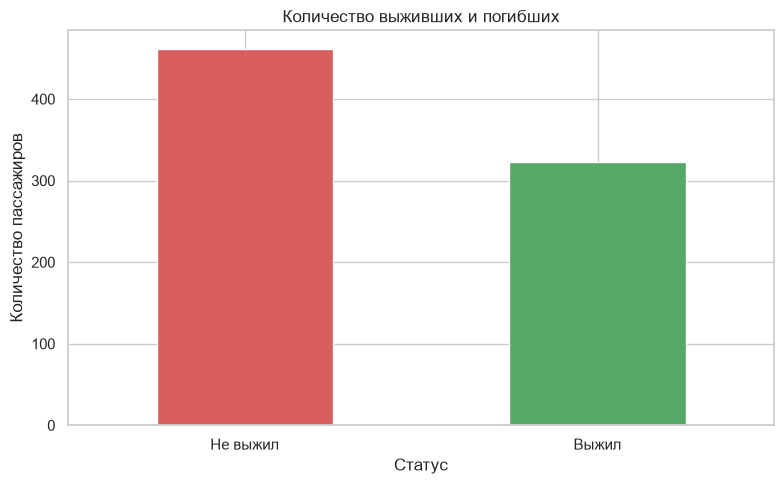

In [36]:
# столбчатый график показывает сколько людей выжило
survival_counts = df_clean['alive'].value_counts().rename(index={'yes': 'Выжил', 'no': 'Не выжил'})
ax = survival_counts.plot(kind='bar', color=['#d95f5f', '#55a868'])
ax.set(title='Количество выживших и погибших', xlabel='Статус', ylabel='Количество пассажиров')
ax.tick_params(axis='x', rotation=0)
plt.tight_layout()
plt.show()

### `hist`

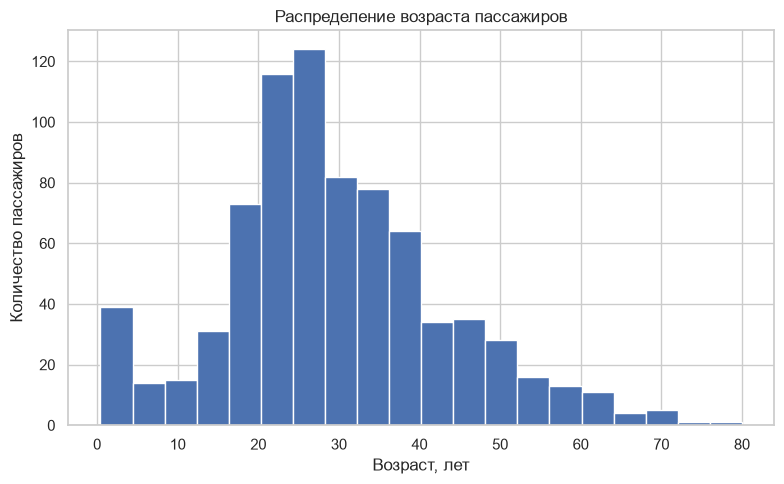

In [37]:
# гистограмма показывает распределение возраста
ax = df_clean['age'].hist(bins=20, color='#4c72b0', edgecolor='white')
ax.set(title='Распределение возраста пассажиров', xlabel='Возраст, лет', ylabel='Количество пассажиров')
plt.tight_layout()
plt.show()

### `boxplot`

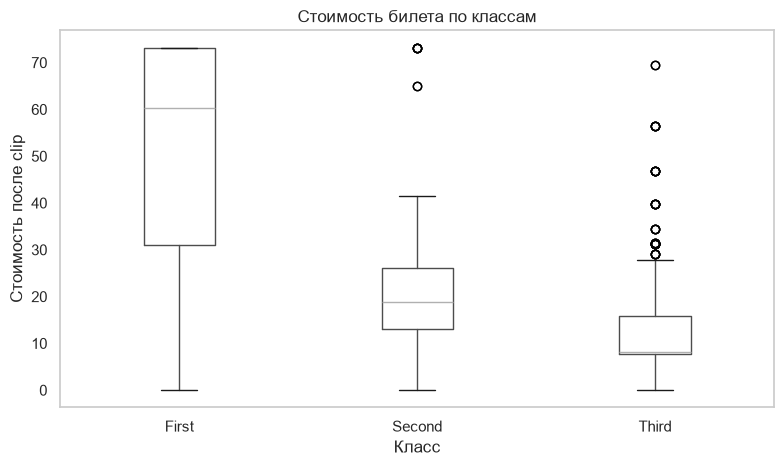

In [38]:
# boxplot сравнивает стоимость билетов между классами
df_clean.boxplot(column='fare', by='class', grid=False)
plt.title('Стоимость билета по классам')
plt.suptitle('')
plt.xlabel('Класс')
plt.ylabel('Стоимость после clip')
plt.tight_layout()
plt.show()

### `sns.scatterplot`

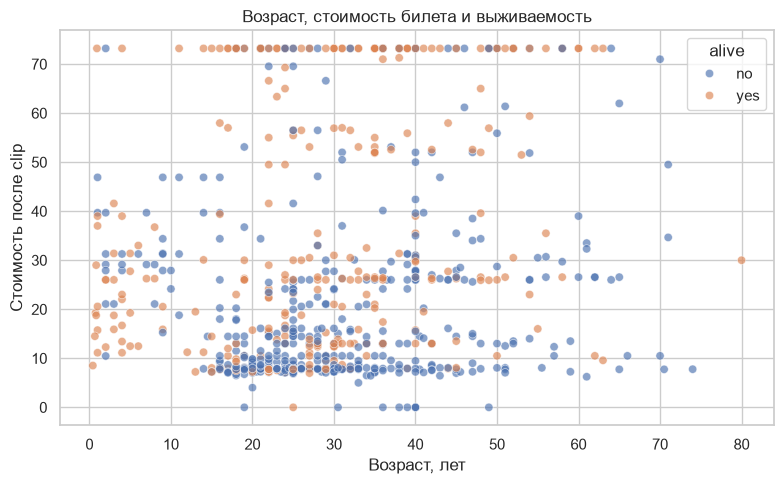

In [39]:
# каждая точка это пассажир, цвет показывает выжил он или нет
sns.scatterplot(data=df_clean, x='age', y='fare', hue='alive', alpha=0.65)
plt.title('Возраст, стоимость билета и выживаемость')
plt.xlabel('Возраст, лет')
plt.ylabel('Стоимость после clip')
plt.tight_layout()
plt.show()

## 8. Корреляции (`corr`)

In [40]:
# корреляцию считаем только для выбранных числовых признаков
numeric_columns = ['survived', 'pclass', 'age', 'sibsp', 'parch', 'fare']
correlation_matrix = df_clean[numeric_columns].corr()
correlation_matrix.round(2)

,survived,pclass,age,sibsp,parch,fare
survived,1.00,-0.33,-0.08,-0.04,0.07,0.31
pclass,-0.33,1.00,-0.40,0.09,0.04,-0.73
age,-0.08,-0.40,1.00,-0.29,-0.19,0.17
sibsp,-0.04,0.09,-0.29,1.00,0.38,0.26
parch,0.07,0.04,-0.19,0.38,1.00,0.24
fare,0.31,-0.73,0.17,0.26,0.24,1.00


### Корреляционная матрица с градиентом

In [41]:
# цветом проще заметить сильные положительные и отрицательные связи
correlation_matrix.style.background_gradient(cmap='coolwarm').format('{:.2f}')

,survived,pclass,age,sibsp,parch,fare
survived,1.00,-0.33,-0.08,-0.04,0.07,0.31
pclass,-0.33,1.00,-0.40,0.09,0.04,-0.73
age,-0.08,-0.40,1.00,-0.29,-0.19,0.17
sibsp,-0.04,0.09,-0.29,1.00,0.38,0.26
parch,0.07,0.04,-0.19,0.38,1.00,0.24
fare,0.31,-0.73,0.17,0.26,0.24,1.00


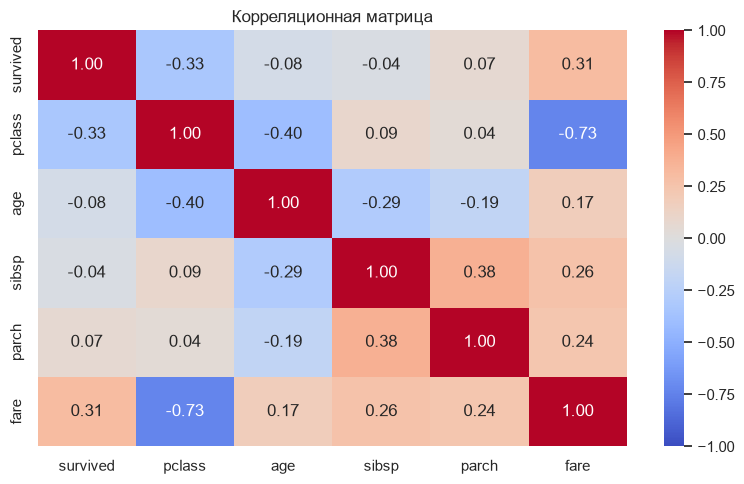

In [42]:
# та же матрица но уже как отдельная тепловая карта
sns.heatmap(correlation_matrix, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Корреляционная матрица')
plt.tight_layout()
plt.show()

In [43]:
# отдельно сортируем связи именно с выживаемостью
correlation_matrix['survived'].drop('survived').sort_values(key=abs, ascending=False)

pclass   -0.332658
fare      0.305976
age      -0.075148
parch     0.070307
sibsp    -0.036589
Name: survived, dtype: float64

## 9. Группировка и агрегирование (`groupby`, `agg`, `pd.pivot_table`)

In [44]:
# собираем статистику отдельно по полу и классу
group_summary = (
    df_clean.groupby(['sex', 'class'])
    .agg(
        passenger_count=('survived', 'size'),
        survival_rate=('survived', 'mean'),
        mean_age=('age', 'mean'),
        mean_fare=('fare_original', 'mean')
    )
    .reset_index()
)
group_summary[['survival_rate', 'mean_age', 'mean_fare']] = (
    group_summary[['survival_rate', 'mean_age', 'mean_fare']].round(2)
)
group_summary

,sex,class,passenger_count,survival_rate,mean_age,mean_fare
0,female,First,93,0.97,34.76,106.52
1,female,Second,73,0.92,28.42,22.19
2,female,Third,127,0.47,21.97,15.70
3,male,First,121,0.37,41.07,67.55
4,male,Second,92,0.18,31.06,21.55
5,male,Third,278,0.16,26.32,12.72


In [45]:
# сводная таблица с долей выживших
survival_pivot = pd.pivot_table(
    df_clean, values='survived', index='sex', columns='class', aggfunc='mean'
).round(3)
survival_pivot

class,First,Second,Third
sex,,,
female,0.968,0.918,0.472
male,0.372,0.185,0.158


## 10. Проверка зависимостей

Проверяется связь между полом и выживаемостью. Нулевая гипотеза: признаки независимы.

### Таблица сопряжённости

In [46]:
# таблица сколько мужчин и женщин выжило или погибло
contingency_table = pd.crosstab(df_clean['sex'], df_clean['alive'])
contingency_table

alive,no,yes
sex,,
female,76,217
male,385,106


### Критерий χ² Пирсона (`chi2_contingency`)

In [47]:
# критерий хи-квадрат проверяет независимы ли пол и выживание
chi2, p_value, degrees_of_freedom, expected = chi2_contingency(contingency_table)
print(f'χ² = {chi2:.3f}')
print(f'p-value = {p_value:.6g}')
print(f'Степени свободы = {degrees_of_freedom}')
print('Вывод:', 'связь статистически значима' if p_value < 0.05 else 'значимая связь не обнаружена')

pd.DataFrame(expected, index=contingency_table.index, columns=contingency_table.columns).round(2)

χ² = 206.400
p-value = 8.38341e-47
Степени свободы = 1
Вывод: связь статистически значима


alive,no,yes
sex,,
female,172.29,120.71
male,288.71,202.29


### Точный критерий Фишера (`fisher_exact`)

In [48]:
# дополнительная проверка для таблицы два на два
odds_ratio, fisher_p = fisher_exact(contingency_table.to_numpy())
print(f'Отношение шансов = {odds_ratio:.3f}')
print(f'p-value Фишера = {fisher_p:.6g}')
print('Вывод:', 'связь статистически значима' if fisher_p < 0.05 else 'значимая связь не обнаружена')

Отношение шансов = 0.096
p-value Фишера = 2.83707e-48
Вывод: связь статистически значима


## Итоговые выводы

- Загружены и изучены 891 строка и 15 признаков.
- Продемонстрированы требуемые операции изменения структуры и кодирования категорий.
- Полные совпадения строк удалены с оговоркой об отсутствии уникального ID.
- Пропуски обработаны, выбросы стоимости ограничены методом IQR.
- Построены четыре вида графиков и корреляционная матрица.
- Выполнены группировки, агрегации и сводная таблица.
- χ² и точный критерий Фишера проверяют связь пола с выживаемостью. Конкретные статистики сохранены в выполненных ячейках.

Статистическая зависимость и корреляция сами по себе не доказывают причинно-следственную связь.